In [1]:
#| label: setup
from latincyreaders import TesseraeReader

CR = TesseraeReader()
FILES = sorted(f for f in CR.fileids() if "cicero." in f)

# When the plaintext-ll texts are ready, this is the only cell that changes:
#   from latincyreaders import TxtdownReader
#   CR = TxtdownReader("~/latincy_data/plaintext-ll")

print(f"{len(FILES)} files of Cicero")
print(FILES[:5])

124 files of Cicero
['cicero.academica.tess', 'cicero.brutus.tess', 'cicero.cum_populo_gratias_egit.tess', 'cicero.de_amicitia.tess', 'cicero.de_divinatione.tess']


## Counting Latin syllables

⟦LLM-DRAFT⟧ Three of the four classic formulas need syllable counts. The 2016
version counted vowel characters; the 2017 sequel patched that with a few
digraph substitutions. Neither handles the two things that actually matter in
Latin: `v` and `j` are consonants, and so is intervocalic `i`. *Troiae* is two
syllables, not three; *iam* is one, not two.

In [2]:
#| label: syllables
import re

VOWELS = "aeiouy"
DIPHTHONGS = ("ae", "oe", "au", "eu", "ei", "ui")


def phon(word):
    """Lower-case and strip non-letters, keeping v/j as consonants."""
    return re.sub(r"[^a-z]", "", word.lower())


def mark_consonantal_i(w):
    """Rewrite consonantal i as j so it is not counted as a nucleus.

    Consonantal i appears word-initially before a vowel (iam, iuvenis) and
    between two vowels (Troiae, maior, eius). Compounds such as con-iugis are
    the known exception and are not caught.
    """
    if len(w) > 1 and w[0] == "i" and w[1] in VOWELS:
        w = "j" + w[1:]
    return re.sub(r"(?<=[aeiouy])i(?=[aeiouy])", "j", w)


def count_syllables(word):
    """Count syllabic nuclei in a Latin word."""
    w = mark_consonantal_i(phon(word))
    if not w:
        return 0
    # the u of qu-/gu- before a vowel is a glide, not a nucleus
    w = re.sub(r"(?<=[qg])u(?=[aeiouy])", "", w)

    count, i = 0, 0
    while i < len(w):
        if w[i] in VOWELS:
            i += 2 if w[i : i + 2] in DIPHTHONGS else 1
            count += 1
        else:
            i += 1
    return count


for w in ["arma", "virumque", "Troiae", "iam", "maior", "Aeneas", "quoque"]:
    print(f"{w:10s} {count_syllables(w)}")

arma       2
virumque   3
Troiae     2
iam        1
maior      2
Aeneas     3
quoque     2


::: {.callout-tip}
## This counter gets validated properly in the companion post

Prose gives you no way to check a syllable count. Verse does: a dactylic
hexameter must have between 12 and 17 syllables. In the [companion post on
Vergil](../vergil-readability/) this same function is checked against all 9,896
lines of the *Aeneid*, where it lands in the metrically possible range 99.4% of
the time — and its apparent failures turn out to be Vergil's famous half-lines.
:::

## The four formulas

⟦LLM-DRAFT⟧ These are the same four as in 2016, and the same caveat applies: the
coefficients were fitted on English, so the absolute scores are meaningless. Only
the ranking they induce is claimed. That caveat used to be the end of the
argument. It isn't any more — see the last section.

In [3]:
#| label: formulas
def ari(c, w, s):
    return 4.71 * (c / w) + 0.5 * (w / s) - 21.43


def gunning_fog(w, s, cw):
    return 0.4 * ((w / s) + 100 * (cw / w))


def flesch_kincaid(w, s, sy):
    return 0.39 * (w / s) + 11.8 * (sy / w) - 15.59


def coleman_liau(c, w, s):
    return 0.0588 * (c / w * 100) - 0.296 * (s / w * 100) - 15.8


def dale_chall(w, s, dw):
    return 0.1579 * (dw / w * 100) + 0.0496 * (w / s)

## Reference word lists

⟦LLM-DRAFT⟧ Dale–Chall marks a word "difficult" if it is absent from a list of
common words. The 2016 talk substituted the DCC Core Latin Vocabulary
[@dcc-core] for Dale and Chall's 3,000 English words, and that is still the right
choice. What is new is the frequency data alongside it: `latincy-words` gives a
ranked lemma list built from UD treebanks, Wiktionary, and Whitaker's Words,
which is what the lexical measures in the next section need.

Note the orthography trap. `latincy-words` normalizes to `u`/`i` (*uirtus*, not
*virtus*), so lookup needs a different normalization from the one syllable
counting needs. Folding `v` to `u` before counting syllables is exactly the bug
that would make *virumque* start with a vowel.

In [4]:
#| label: wordlists
from pathlib import Path


def normalize_lemma(text):
    """Fold to the u/i orthography of latincy-words. LOOKUP ONLY."""
    return text.lower().replace("j", "i").replace("v", "u")


DCC = {
    normalize_lemma(line.strip())
    for line in Path("dcc-core-vocab.txt").read_text().splitlines()
    if line.strip() and not line.startswith("#")
}

LEMMA_RANK = {}
with open("latin-lemma-ranks.tsv") as f:
    next(f)
    for line in f:
        rank, lemma = line.rstrip("\n").split("\t")
        LEMMA_RANK.setdefault(normalize_lemma(lemma), int(rank))

print(f"DCC core lemmas: {len(DCC)}")
print(f"ranked lemmas:   {len(LEMMA_RANK):,}")

DCC core lemmas: 959
ranked lemmas:   49,560


## Lexical measures after Gruber-Miller and Mulligan

⟦LLM-DRAFT⟧ Here is where the intervening scholarship changes the analysis rather
than just the tooling. Gruber-Miller and Mulligan [@gruber-miller-mulligan-2022]
argue that lexical complexity in Latin is better captured by five measures —
word length, word frequency, lexical sophistication, lexical density, and
lexical variation — combined into a single score they call *LexR*. That is a
Latin-specific replacement for the Dale–Chall stand-in, built on the observation
that readers need to know 95–98% of the words in a text to understand it.

I compute their five measures below. The composite is **my own z-score
combination, not their published weighting** — I have not reproduced *LexR*
itself, and the score below should not be cited as such.

For lexical variation I use MATTR [@covington-mcfall-2010] rather than a raw
type-token ratio, because TTR falls as texts get longer and Cicero's works range
from a few hundred to tens of thousands of words. Comparing raw TTR across them
would mostly measure length.

In [5]:
#| label: lexical
import math
from collections import Counter

CONTENT_POS = {"NOUN", "PROPN", "VERB", "ADJ", "ADV"}


def mattr(tokens, window=50):
    """Moving-average type-token ratio; length-robust unlike raw TTR."""
    if len(tokens) <= window:
        return len(set(tokens)) / len(tokens) if tokens else 0.0
    counts = Counter(tokens[:window])
    total, n = len(counts) / window, 1
    for i in range(window, len(tokens)):
        out, inc = tokens[i - window], tokens[i]
        counts[out] -= 1
        if not counts[out]:
            del counts[out]
        counts[inc] += 1
        total += len(counts) / window
        n += 1
    return total / n


def lexical_measures(sents, cutoff=1000):
    """The five measures named by Gruber-Miller and Mulligan (2022)."""
    tokens, lemmas, content = [], [], 0
    for sent in sents:
        for tok in sent:
            if not tok.is_alpha:
                continue
            tokens.append(normalize_lemma(tok.text))
            lemmas.append(normalize_lemma(tok.lemma_))
            content += tok.pos_ in CONTENT_POS

    n = len(tokens)
    if not n:
        return None
    ranks = [LEMMA_RANK.get(lm) for lm in lemmas]
    known = [r for r in ranks if r]

    return {
        "word_length": sum(len(t) for t in tokens) / n,
        "mean_log_rank": (sum(math.log10(r) for r in known) / len(known)) if known else 0.0,
        "sophistication": sum(1 for r in ranks if r is None or r > cutoff) / n,
        "density": content / n,
        "variation": mattr(tokens),
    }

## Running the corpus

⟦LLM-DRAFT⟧ Roughly 7.6 MB of Cicero through `la_core_web_lg` takes about half an
hour, so the per-work measurements are checkpointed to CSV. Delete
`cicero-metrics.csv` to force a rebuild.

In [6]:
#| label: build
import pandas as pd

CACHE = Path("cicero-metrics.csv")


def text_counts(sents):
    """(chars, words, sentences, syllables, complex words) over spaCy sents."""
    chars = words = syls = complex_words = n_sents = 0
    for sent in sents:
        n_sents += 1
        for tok in sent:
            if not tok.is_alpha:
                continue
            words += 1
            chars += len(tok.text)
            s = count_syllables(tok.text)
            syls += s
            complex_words += s > 3
    return chars, words, n_sents, syls, complex_words


def work_title(fileid):
    stem = Path(fileid).stem.replace("cicero.", "")
    return stem.replace(".part.", " ").replace("_", " ")


SENTS_CACHE = Path("cicero-hardest-sentences.csv")


def sentence_citations(sent, lines):
    """Tesserae citations overlapping a spaCy sentence."""
    return [l._.citation for l in lines
            if l.start < sent.end and l.end > sent.start]


if CACHE.exists() and SENTS_CACHE.exists():
    metrics = pd.read_csv(CACHE)
    hardest = pd.read_csv(SENTS_CACHE)
else:
    rows, sent_rows = [], []
    for fid in FILES:
        doc = next(iter(CR.docs([fid])))
        sents = list(doc.sents)
        lines = list(doc.spans["lines"])
        title = work_title(fid)

        # per-sentence scores, kept for the "hardest sentence" question
        for sent in sents:
            sc, sw, _, _, _ = text_counts([sent])
            if sw < 30:       # a long-sentence contest needs a floor
                continue
            cits = sentence_citations(sent, lines)
            sent_rows.append({
                "title": title,
                "words": sw,
                "ari": ari(sc, sw, 1),
                "citation_first": cits[0] if cits else "",
                "citation_last": cits[-1] if cits else "",
                "text": " ".join(sent.text.split()),
            })

        c, w, s, sy, cw = text_counts(sents)
        if w < 500:           # skip fragments too short to score stably
            continue
        dw = sum(
            1 for sent in sents for t in sent
            if t.is_alpha and normalize_lemma(t.lemma_) not in DCC
        )
        row = {
            "fileid": fid,
            "title": title,
            "chars": c, "words": w, "sents": s,
            "sylls": sy, "complex": cw, "difficult": dw,
            "ari": ari(c, w, s),
            "fog": gunning_fog(w, s, cw),
            "fk": flesch_kincaid(w, s, sy),
            "cl": coleman_liau(c, w, s),
            "dc": dale_chall(w, s, dw),
        }
        row.update(lexical_measures(sents))
        rows.append(row)

    metrics = pd.DataFrame(rows)
    metrics.to_csv(CACHE, index=False)
    hardest = (
        pd.DataFrame(sent_rows).sort_values("ari", ascending=False).head(50)
    )
    hardest.to_csv(SENTS_CACHE, index=False)

print(f"{len(metrics)} works scored")
metrics[["title", "words", "sents", "ari", "dc"]].head()

124 works scored


,title,words,sents,ari,dc
0,academica,4902,241,14.887254,5.189909
1,brutus,24742,1647,12.286628,5.409616
2,cum populo gratias egit,2636,108,18.172467,5.409693
3,de amicitia,9341,582,12.387723,4.854715
4,de divinatione,27752,1973,11.981457,5.550396


In [7]:
#| label: composite
import numpy as np

LEX_KEYS = {
    "word_length": True,
    "mean_log_rank": True,
    "sophistication": True,
    "density": True,
    "variation": True,
}

z = np.zeros(len(metrics))
for key, harder_is_higher in LEX_KEYS.items():
    col = metrics[key]
    zk = (col - col.mean()) / (col.std(ddof=0) or 1.0)
    z += zk if harder_is_higher else -zk
metrics["lex_composite"] = z / len(LEX_KEYS)

## Results

⟦LLM-DRAFT⟧ The Twitter poll in the 2016 talk picked *In Catilinam* I as the work
teachers most often read with intermediate students, so the 2016 charts
highlighted it as an informal sanity check: a measure that ranks the standard
intermediate text among the hardest Cicero is telling us something about the
measure.

One thing does not survive the corpus change. The Latin Library gave each
Catilinarian its own file; Tesserae keeps all four in a single
`cicero.in_catilinam.tess`. So the highlight below is all four orations
together, not the first alone. Splitting them is possible — the citations are
there, `<cic. catil. 1.1>` and so on — but it is a different operation from
reading files off disk, and worth being explicit about rather than quietly
comparing a 2016 number for one speech against a 2026 number for four.

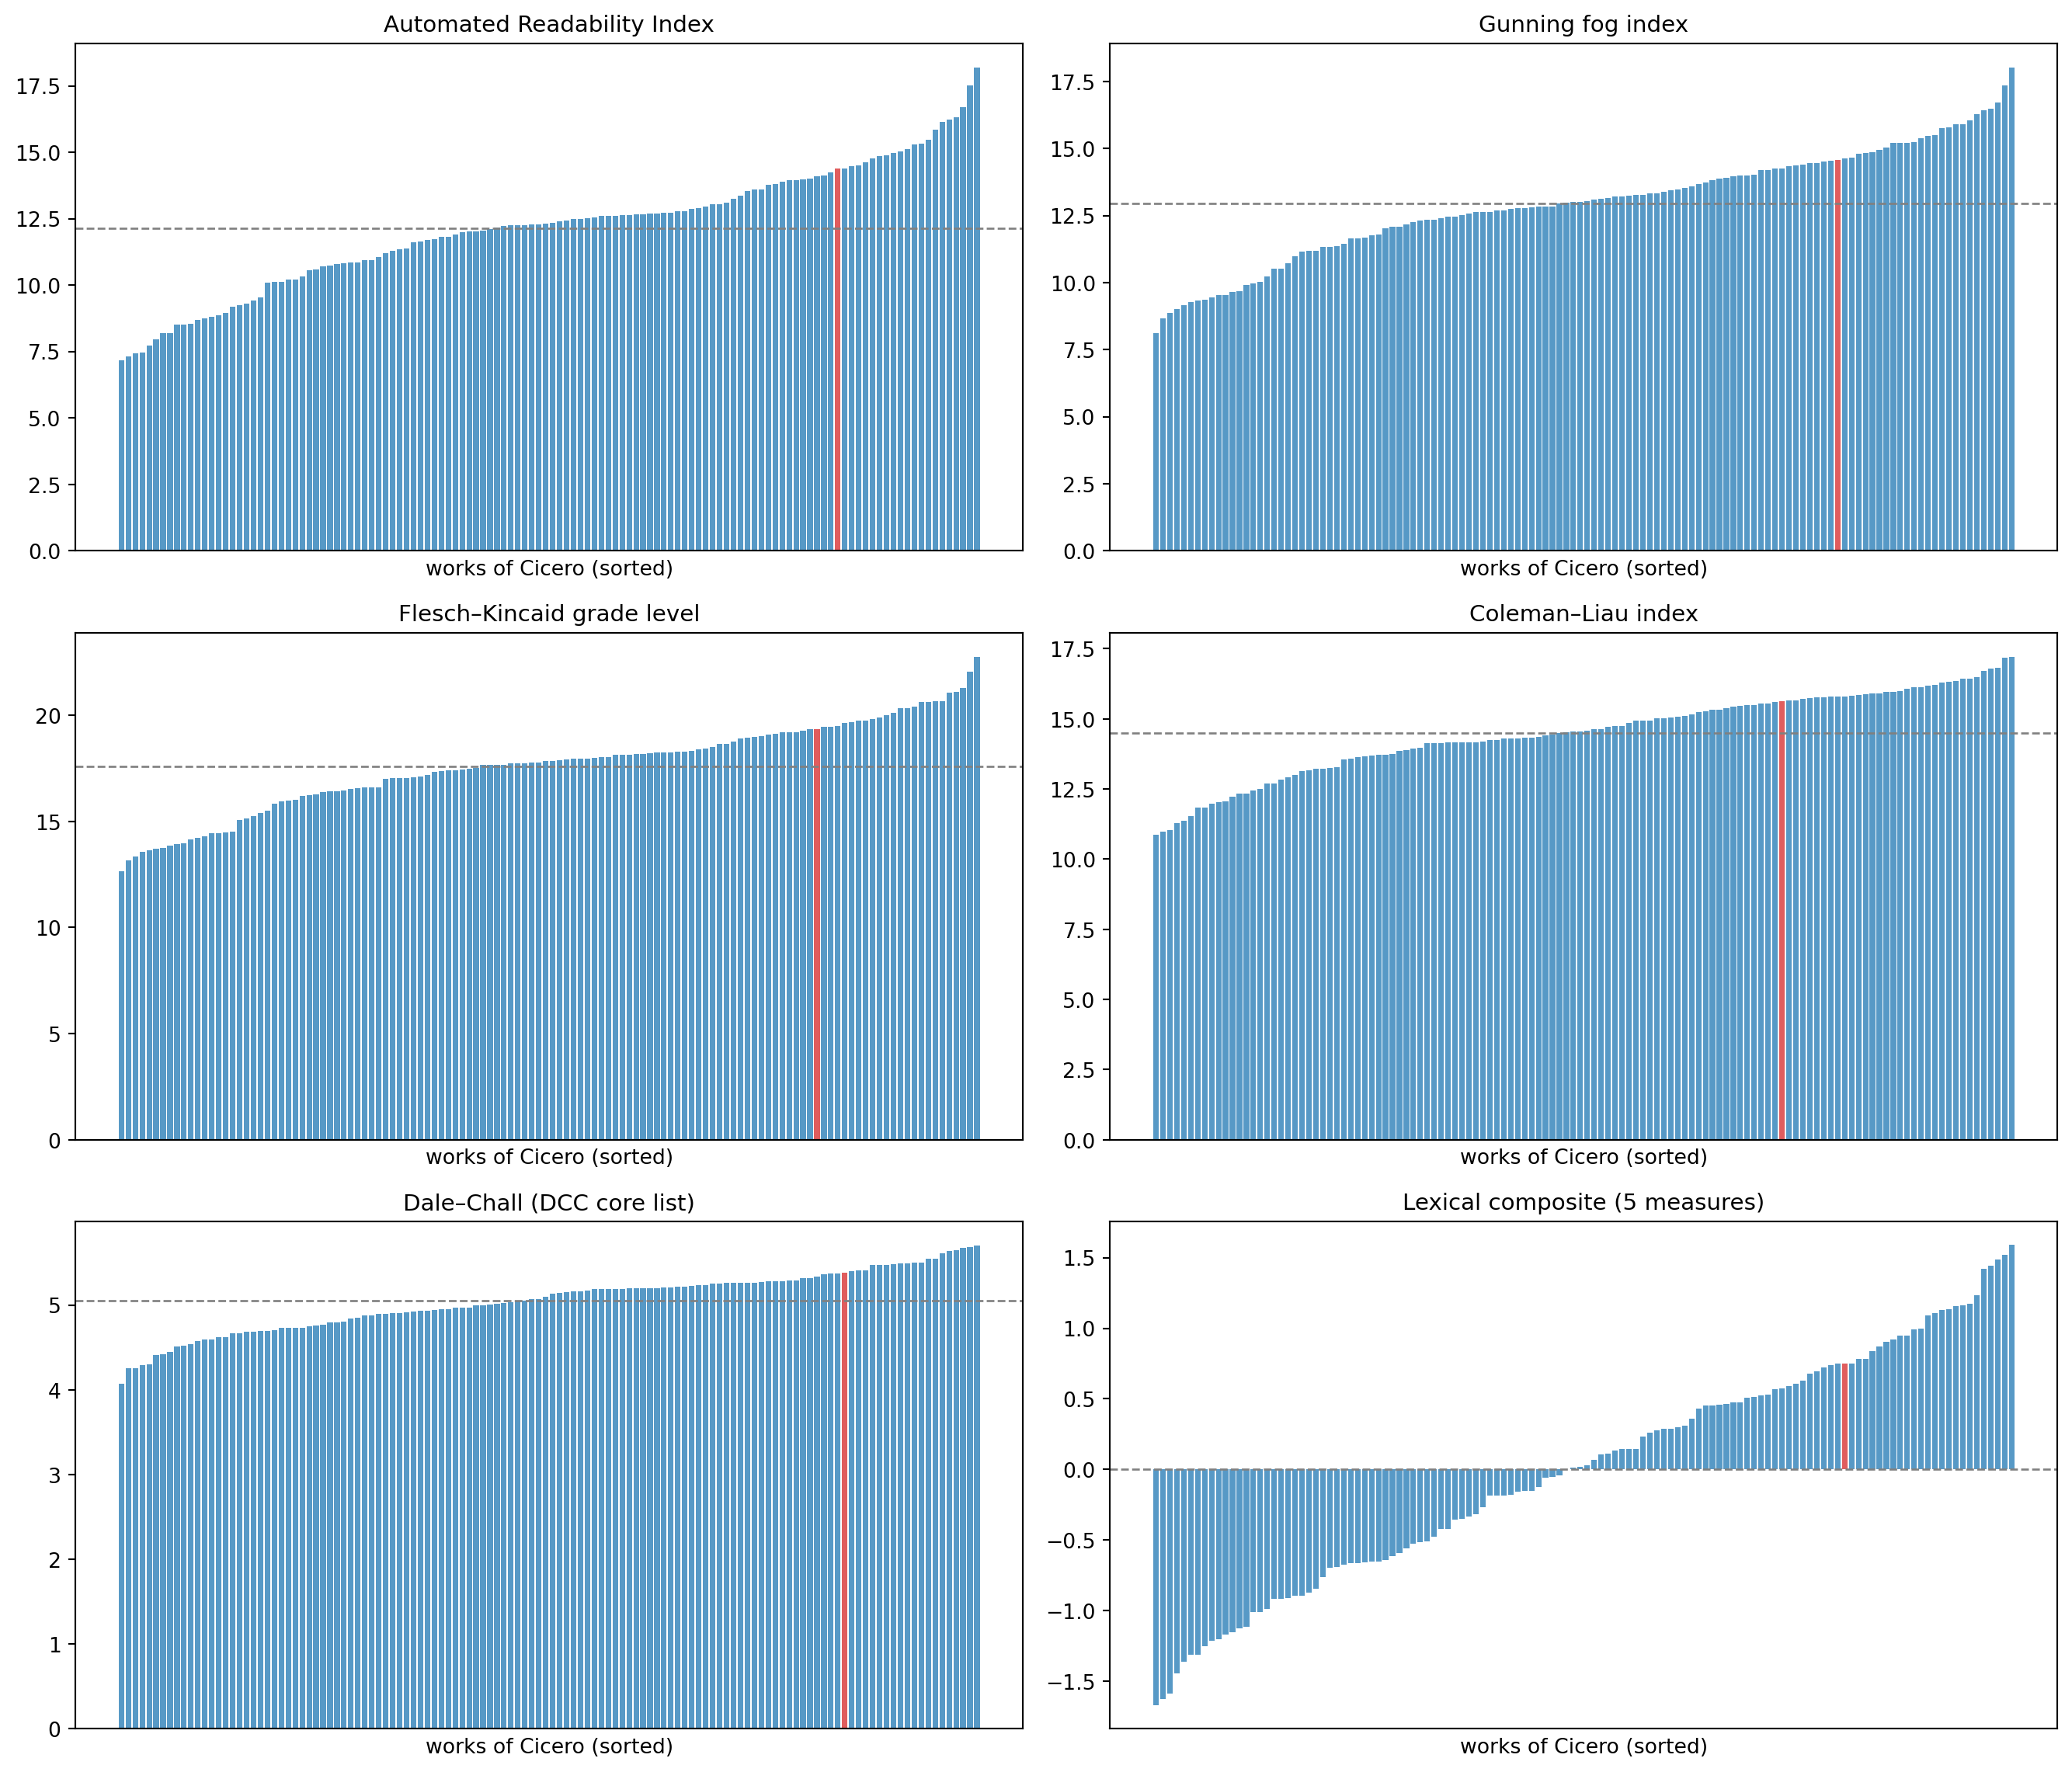

In [8]:
#| label: fig-rankings
#| fig-cap: "Cicero's works ranked by six readability measures. *In Catilinam* (all four) highlighted."
import matplotlib.pyplot as plt

TESTS = [
    ("ari", "Automated Readability Index"),
    ("fog", "Gunning fog index"),
    ("fk", "Flesch–Kincaid grade level"),
    ("cl", "Coleman–Liau index"),
    ("dc", "Dale–Chall (DCC core list)"),
    ("lex_composite", "Lexical composite (5 measures)"),
]
HIGHLIGHT = "in catilinam"      # all four orations in Tesserae, not just I

fig, axes = plt.subplots(3, 2, figsize=(14, 12))
for ax, (col, label) in zip(axes.flat, TESTS):
    d = metrics.sort_values(col)
    colors = [
        "tab:red" if HIGHLIGHT in t else "tab:blue" for t in d["title"]
    ]
    ax.bar(range(len(d)), d[col], color=colors, alpha=0.75)
    ax.axhline(d[col].mean(), color="gray", ls="dashed", lw=1)
    ax.set_title(label, fontsize=11)
    ax.set_xticks([])
    ax.set_xlabel("works of Cicero (sorted)")
fig.tight_layout()
plt.show()

In [9]:
#| label: tbl-extremes
#| tbl-cap: "Five easiest and five hardest works by the lexical composite."
cols = ["title", "words", "ari", "dc", "lex_composite"]
d = metrics.sort_values("lex_composite")
pd.concat([d[cols].head(5), d[cols].tail(5)]).round(2)

,title,words,ari,dc,lex_composite
6,de fato,4964,11.30,4.69,-1.67
9,de finibus bonorum et malorum 3,7907,14.12,4.84,-1.62
59,letters to atticus 11,6941,7.97,4.07,-1.58
43,epistulae ad familiares 14.ad terentiam uxorem,2463,7.43,4.26,-1.44
116,topica,6845,10.55,4.90,-1.36
83,philippicae 14,3391,14.46,5.02,1.42
85,philippicae 3,3748,13.26,5.19,1.44
87,philippicae 5,5126,12.65,5.10,1.49
82,philippicae 13,5154,12.03,5.50,1.52
91,philippicae 9,1643,12.72,5.65,1.59


In [10]:
#| label: tbl-agreement
#| tbl-cap: "Rank correlation between measures (Spearman)."
metrics[[c for c, _ in TESTS]].corr(method="spearman").round(2)

,ari,fog,fk,cl,dc,lex_composite
ari,1.00,0.98,0.99,0.86,0.47,0.34
fog,0.98,1.00,0.98,0.84,0.43,0.29
fk,0.99,0.98,1.00,0.89,0.49,0.37
cl,0.86,0.84,0.89,1.00,0.64,0.66
dc,0.47,0.43,0.49,0.64,1.00,0.73
lex_composite,0.34,0.29,0.37,0.66,0.73,1.00


In [11]:
#| label: tbl-vs-length
#| tbl-cap: "Spearman correlation of each measure with words per sentence."
metrics["wps"] = metrics["words"] / metrics["sents"]
pd.DataFrame(
    {"vs. words-per-sentence": [metrics[c].corr(metrics["wps"], method="spearman")
                                for c, _ in TESTS]},
    index=[c for c, _ in TESTS],
).round(2).sort_values("vs. words-per-sentence", ascending=False)

,vs. words-per-sentence
ari,0.91
fog,0.89
fk,0.88
cl,0.61
dc,0.26
lex_composite,0.04


⟦LLM-DRAFT⟧ Read the two correlation tables before the bar charts. ARI, Gunning
fog, and Flesch–Kincaid agree with each other at 0.98–0.99 — they are not three
measurements, they are one measurement computed three ways. All three correlate
with words-per-sentence at 0.88–0.91. The lexical composite correlates with
words-per-sentence at **0.04**: it is very nearly orthogonal to everything the
classic formulas are picking up.

That is the case for bothering with the lexical side at all. If you want to know
whether a text is hard *because of its vocabulary*, none of the four classic
formulas will tell you — they will tell you about sentence length, and then
tell you again, and again.

The extremes are legible. The lexically easiest works are *De fato*, *De
finibus* 3, and *Letters to Atticus* 11; the hardest are the *Philippics*.
*In Catilinam* — the text the 2016 poll named as standard intermediate reading —
sits at +0.75 on the composite, meaningfully above the Cicero average. Whatever
makes it a good first speech, it is not that its vocabulary is easy.

In [12]:
#| label: tbl-hardest
#| tbl-cap: "The ten highest-scoring sentences in Cicero, by ARI, with citations."
top = hardest.head(10).copy()
top["passage"] = top["text"].str.slice(0, 90) + "…"
top[["title", "citation_first", "citation_last", "words", "ari", "passage"]].round(1)

,title,citation_first,citation_last,words,ari,passage
0,divinatio in c verrem 6,<cic. ver. 2.5.136>,<cic. ver. 2.5.137>,204,107.8,"cum tibi haec diceret, 'tu in provincia populi..."
1,de domo sua,<cic. red. dom. 144>,<cic. red. dom. 145>,203,106.6,"Quocirca te, Capitoline, quem propter benefici..."
2,letters to quintus,<cic. quint. 1.1.25>,<cic. quint. 1.1.26>,183,98.2,cuius quidem generis constare inter omnis vide...
3,divinatio in c verrem 6,<cic. ver. 2.5.186>,<cic. ver. 2.5.188>,173,90.8,"teque, Ceres et Libera, quarum sacra, sicut op..."
4,de oratore 2,<cic. orat. 2.69>,<cic. orat. 2.71>,173,89.7,"ut in pictura, qui hominum unam speciem pinger..."
5,pro a cluentio,<cic. clu. 125>,<cic. clu. 125>,139,76.9,dum vero eum fuisse Oppianicum constabit qui t...
6,philippicae 3,<cic. phil. 3.30>,<cic. phil. 3.30>,135,75.4,quid hic victor non audebit qui nullam adeptus...
7,brutus,<cic. brut. 93>,<cic. brut. 93>,138,75.2,"dicam de ceteris, quorum nemo erat qui videret..."
8,cum populo gratias egit,<cic. red. pop. 13>,<cic. red. pop. 13>,135,73.8,"ego, cum homines in tribunali Aurelio palam co..."
9,tusculanae disputationes 1,<cic. tusc. 1.68>,<cic. tusc. 1.69>,132,73.4,Ut cum videmus speciem primum candoremque cael...


In [13]:
#| label: winner
win = hardest.iloc[0]
print(f"{win['title']}  {win['citation_first']} … {win['citation_last']}")
print(f"ARI {win['ari']:.1f} | {win['words']} words")
print()
print(win["text"][:1200])

divinatio in c verrem 6  <cic. ver. 2.5.136> … <cic. ver. 2.5.137>
ARI 107.8 | 204 words

cum tibi haec diceret, 'tu in provincia populi Romani praetor, cum tibi maritimum bellum esset administrandum, Mamertinis ex foedere quam deberent navem per triennium remisisti, tibi apud eosdem privata navis oneraria maxima publice est aedificata, tu a civitatibus pecunias classis nomine coegisti, tu pretio remiges dimisisti, tu, navis cum esset ab quaestore et ab legato capta praedonum, archipiratam ab oculis omnium removisti, tu, qui cives Romani esse dicerentur, qui a multis cognoscerentur, securi ferire potuisti, tu tuam domum piratas abducere, tu in iudicium archipiratam domo producere ausus es, tu in provincia tam splendida, tu apud socios fidelissimos, civis Romanos honestissimos, in metu periculoque provinciae dies continuos compluris in litore conviviisque iacuisti, te per eos dies nemo tuae domi convenire, nemo in foro videre potuit, tu sociorum atque amicorum ad ea convivia matres fami

⟦LLM-DRAFT⟧ The winner is *Verrines* 2.5.136–137: a single 204-word sentence,
ARI 107.8, and — unlike the 2016 answer — a claim you can go and check.

The 2016 answer was *De oratore* 3.202–205, and it does not survive. It is not
in the top fifty; the highest-scoring *De oratore* sentence is at 2.69. The
reason is the preprocessing. Stripped of punctuation, sections 202–205 read as
one continuous run, and a heuristic tokenizer had no way to divide them. With
real punctuation, *De oratore* 3 breaks into 893 sentences across 16,766 words,
and its "hardest sentence" turns out to have been four sections glued together
by the pipeline rather than by Cicero.

That is worth stating plainly: the punchline of the 2016 talk was an artifact of
its own preprocessing. This is what it costs when the load-bearing variable in
every formula you use is manufactured upstream.